# Comparing Different Search Strategies: Maze

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


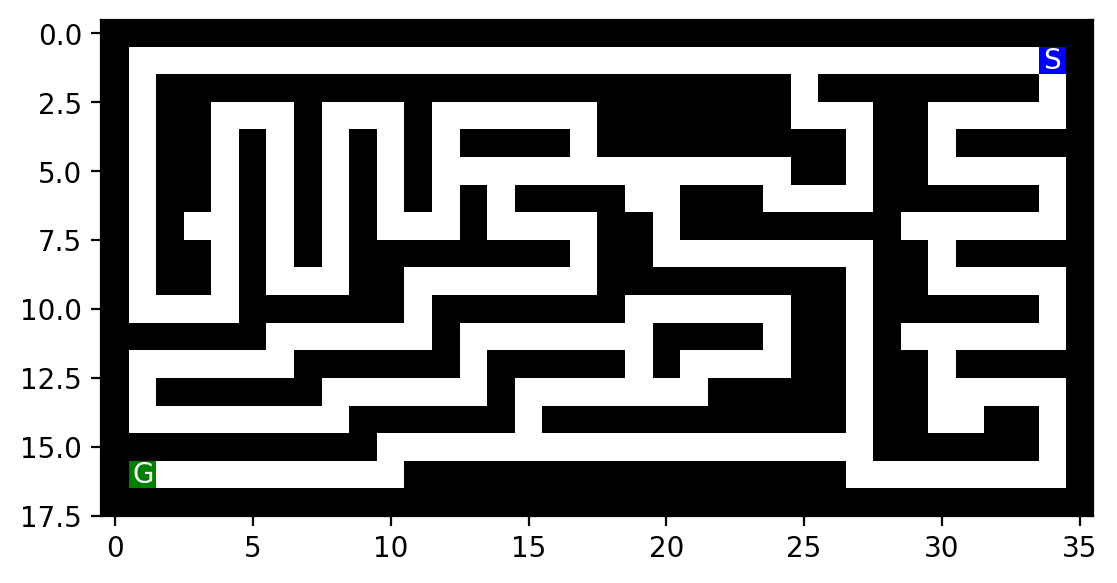

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments - Uninformed Search

### BFS

In [3]:
%time result = ts.best_first_search(maze, strategy = "BFS", animation = True)
ts.animate_maze(result)

CPU times: user 7.57 ms, sys: 449 μs, total: 8.02 ms
Wall time: 8.14 ms
Path length: 68
Reached squares: 269
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


### DFS 

This implementation does not use a reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we can end up in an infinite loop.

In [4]:
ts.set_order("NESW")

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 3.04 ms, sys: 156 μs, total: 3.2 ms
Wall time: 3.06 ms
Path length: 152
Reached squares: 153
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory so they are shown white.

The exploration order (order used in the expand function) is very important for DFS! DFS uses LIFO so the directions come from the stack in reverse order.

I set the exploration order so that South will be explored before West.

In [5]:
ts.set_order("ENWS")

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 1.5 ms, sys: 61 μs, total: 1.56 ms
Wall time: 1.51 ms
Path length: 76
Reached squares: 76
Action sequence: ['S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'N', 'E', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


The best exploration order depends on the Maze, so we probably should rather use random exploration. Here the order is randomized in at each step. It will produce sometimes give good and sometimes bad solutions and can be used with multi[ple restarts.

In [6]:
ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True, animation = True)
ts.animate_maze(result)

CPU times: user 3.09 ms, sys: 0 ns, total: 3.09 ms
Wall time: 3.02 ms
Path length: 68
Reached squares: 118
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


## Experiments - Informed Search

### Greedy Best-First Search (GBFS)

Walks towards the goal using the heuristic. It is greedy and not guaranteed to find the optimal solution.

In [7]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

In [8]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", animation = True)
ts.animate_maze(result)

CPU times: user 2.44 ms, sys: 0 ns, total: 2.44 ms
Wall time: 2.3 ms
Path length: 152
Reached squares: 155
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'E', 'S', 'S', 'S', 'S', 'E', 'E', 'N', 'N', 'E', 'E', 'S', 'S', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'N', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'W', 'W', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


### A* Search

Uses an admissible heuristic and is guaranteed to find the optimal solution. It needs to explore a little more compared to GBFS. 

In [9]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", animation = True)
ts.animate_maze(result)

CPU times: user 82 μs, sys: 4.31 ms, total: 4.39 ms
Wall time: 4.15 ms
Path length: 68
Reached squares: 220
Action sequence: ['W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'S', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


---
# BÀI 3 — PHẦN TRỰC QUAN: BFS VÀ DFS

Notebook gốc minh họa animation BFS/DFS và các phương pháp tìm kiếm có thông tin. Phần bổ sung dưới đây chỉ tập trung yêu cầu **Bài 3**.

Các frame dùng `P` (đường đi sau cùng), `.` (ô đã mở rộng), `F` (frontier), `S` và `G`. Animation hiển thị một số **khung hình lấy mẫu**, không nhất thiết chứa từng lần mở rộng vì cần giữ dung lượng notebook hợp lý. Dữ liệu và số liệu thống kê vẫn dựa trên toàn bộ quá trình chạy tìm kiếm.

In [10]:
import tree_search_solution as ts
import maze_helper as mh
import random
import pandas as pd
from IPython.display import display

with open('small_maze.txt', encoding='utf-8') as f:
    maze_anim_bai3 = mh.parse_maze(f.read())

ts.set_order('NESW')
bfs_anim = ts.best_first_search(maze_anim_bai3, strategy='BFS', animation=True)
print('BFS: path cost =', bfs_anim['path_cost'],
      '| expanded =', bfs_anim['n_expanded'],
      '| max frontier =', bfs_anim['max_frontier'])
display(ts.animate_maze(bfs_anim))

BFS: path cost = 19 | expanded = 92 | max frontier = 9
Path length: 19
Reached squares: 92
Action sequence: ['E', 'E', 'S', 'S', 'W', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


In [11]:
random.seed(20261010)
ts.set_order(random=True)
dfs_anim = ts.DFS(maze_anim_bai3, max_tries=30000, check_cycle=True, animation=True)
print('DFS: path cost =', dfs_anim['path_cost'],
      '| expanded =', dfs_anim['n_expanded'],
      '| max frontier =', dfs_anim['max_frontier'])
display(ts.animate_maze(dfs_anim))

DFS: path cost = 49 | expanded = 73 | max frontier = 6
Path length: 49
Reached squares: 73
Action sequence: ['W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'E', 'E', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'W', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


## Theo dõi frontier và đường đi trên animation

- **BFS:** Các trạng thái được xét theo tầng (FIFO). Đường đi cuối cùng là một trong những đường ngắn nhất theo số bước đối với thiết lập chi phí đồng nhất.
- **DFS:** Ưu tiên mở rộng trạng thái được thêm vào sau cùng (LIFO); thứ tự mở rộng khác BFS và kết quả phụ thuộc thứ tự sinh con.
- **Kết quả mở rộng:** Vùng xám biểu diễn ô được thăm/ghi nhận để trực quan hóa. Đối với DFS kiểm tra chu trình theo đường đi, những ô này là **lịch sử hiển thị**, không đồng nghĩa thuật toán đang giữ tất cả chúng trong tập `reached` để loại bỏ trạng thái lặp.

**Lưu ý:** Kích thước frontier và số lần mở rộng là chỉ số được tính lúc chạy, không suy ra chính xác chỉ từ số lượng ô có màu trong khung hình.

In [12]:
summary_animation = pd.DataFrame([
    {'Thuật toán':'BFS', 'Path cost':bfs_anim['path_cost'],
     'Nút mở rộng':bfs_anim['n_expanded'], 'Max frontier':bfs_anim['max_frontier'],
     'Số frame lưu':len(bfs_anim['maze_anim'])},
    {'Thuật toán':'DFS (random)', 'Path cost':dfs_anim['path_cost'],
     'Nút mở rộng':dfs_anim['n_expanded'], 'Max frontier':dfs_anim['max_frontier'],
     'Số frame lưu':len(dfs_anim['maze_anim'])},
])
display(summary_animation)

,Thuật toán,Path cost,Nút mở rộng,Max frontier,Số frame lưu
0,BFS,19,92,9,26
1,DFS (random),49,73,6,24
